(1382, 20)


,avg_outflow,avg_inflow,total_grid,Am,BOD,COD,TN,T,TM,Tm,SLP,H,PP,VV,V,VM,VG,year,month,day
0,2.941,2.589,175856,27.0,365.0,730.0,60.378,19.3,25.1,12.6,0.0,56,1.52,10.0,26.9,53.5,79.5,2014,1,1
1,2.936,2.961,181624,25.0,370.0,740.0,60.026,17.1,23.6,12.3,0.0,63,0.00,10.0,14.4,27.8,0.0,2014,1,2
2,2.928,3.225,202016,42.0,418.0,836.0,64.522,16.8,27.2,8.8,0.0,47,0.25,10.0,31.9,61.1,77.8,2014,1,5
3,2.928,3.354,207547,36.0,430.0,850.0,63.000,14.6,19.9,11.1,0.0,49,0.00,10.0,27.0,38.9,53.5,2014,1,6
4,2.917,3.794,202824,46.0,508.0,1016.0,65.590,13.4,19.1,8.0,0.0,65,0.00,10.0,20.6,35.2,53.5,2014,1,7


,BOD,COD,TN
count,1382.000000,1382.000000,1382.000000
mean,382.061708,845.960434,62.740752
std,85.996012,145.416540,3.571035
min,140.000000,360.000000,40.000000
25%,330.000000,751.250000,61.396000
50%,360.000000,845.000000,62.957500
75%,422.980000,920.000000,64.366000
max,850.000000,1700.000000,92.000000


,BOD,COD,TN
avg_outflow,-0.12,-0.02,-0.06
avg_inflow,-0.12,0.02,-0.04
total_grid,-0.14,0.00,-0.17
Am,0.16,0.28,0.34
T,0.15,0.08,0.27
TM,0.14,0.09,0.26
Tm,0.13,0.05,0.23
SLP,-0.01,0.00,0.01
H,-0.09,-0.15,-0.21
PP,0.00,-0.06,-0.01


1105 277
BOD: R2=-0.691  RMSE=76.12  MAE=61.57
COD: R2=-0.115  RMSE=138.85  MAE=109.01
TN: R2=-0.004  RMSE=2.85  MAE=1.98


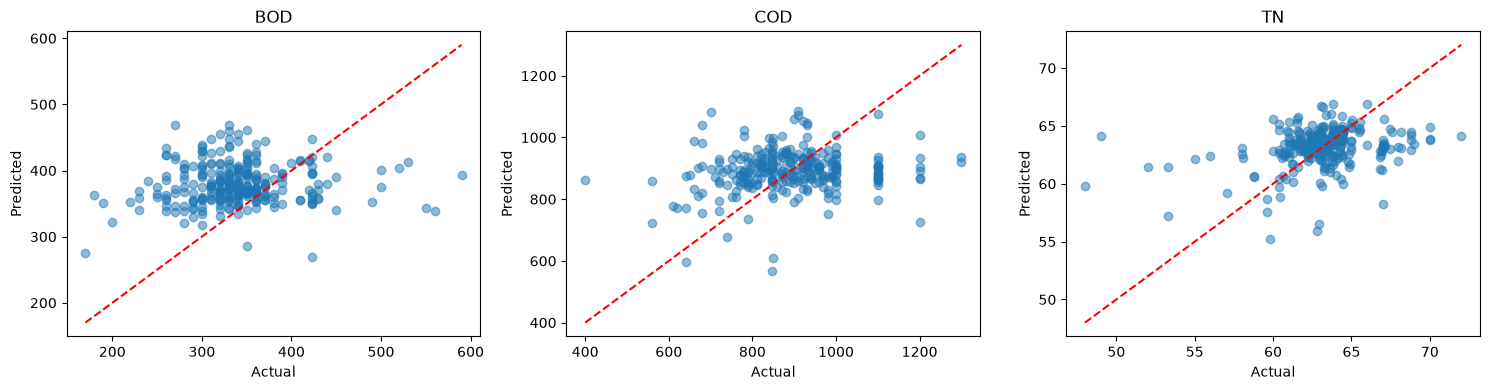

In [9]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/Data-Melbourne_F.csv")
print(df.shape)
display(df.head())
display(df[["BOD", "COD", "TN"]].describe())

corr = df.corr(numeric_only=True)[["BOD", "COD", "TN"]].drop(["BOD", "COD", "TN"])
display(corr.round(2))

df["date"] = pd.to_datetime(df[["year", "month", "day"]])
df = df.sort_values("date").reset_index(drop=True)

targets = ["BOD", "COD", "TN"]
features = [c for c in df.columns if c not in targets + ["date"]]

split = int(len(df) * 0.8)
train, test = df.iloc[:split], df.iloc[split:]
X_train, X_test = train[features], test[features]
y_train, y_test = train[targets], test[targets]
print(len(train), len(test))


from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

model = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)
pred = model.predict(X_test)

for i, t in enumerate(targets):
    r2 = r2_score(y_test[t], pred[:, i])
    rmse = np.sqrt(mean_squared_error(y_test[t], pred[:, i]))
    mae = mean_absolute_error(y_test[t], pred[:, i])
    print(f"{t}: R2={r2:.3f}  RMSE={rmse:.2f}  MAE={mae:.2f}")
    
    
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, t in enumerate(targets):
    axes[i].scatter(y_test[t], pred[:, i], alpha=0.5)
    lo, hi = y_test[t].min(), y_test[t].max()
    axes[i].plot([lo, hi], [lo, hi], "r--")
    axes[i].set_title(t); axes[i].set_xlabel("Actual"); axes[i].set_ylabel("Predicted")
plt.tight_layout(); plt.show()




In [10]:
# Baselines: how good is "do nothing smart"?
for t in targets:
    mean_r2 = r2_score(y_test[t], np.full(len(y_test), y_train[t].mean()))
    prev_r2 = r2_score(df[t].iloc[split:], df[t].shift(1).iloc[split:])
    print(f"{t}: train-mean R2={mean_r2:.3f} | previous-record R2={prev_r2:.3f}")

# Better features: drop year/day, add lags and 7-record rolling averages
df2 = df.copy()
for c in ["BOD", "COD", "TN", "avg_inflow", "avg_outflow", "Am"]:
    df2[f"{c}_lag1"] = df2[c].shift(1)
    df2[f"{c}_roll7"] = df2[c].shift(1).rolling(7).mean()
df2 = df2.dropna().reset_index(drop=True)

features2 = [c for c in df2.columns if c not in targets + ["date", "year", "day"]]
split2 = int(len(df2) * 0.8)
tr, te = df2.iloc[:split2], df2.iloc[split2:]

model2 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
model2.fit(tr[features2], tr[targets])
pred2 = model2.predict(te[features2])

for i, t in enumerate(targets):
    print(f"{t}: R2={r2_score(te[t], pred2[:, i]):.3f}  "
          f"RMSE={np.sqrt(mean_squared_error(te[t], pred2[:, i])):.2f}  "
          f"MAE={mean_absolute_error(te[t], pred2[:, i]):.2f}")

BOD: train-mean R2=-0.843 | previous-record R2=-0.074
COD: train-mean R2=-0.168 | previous-record R2=-0.345
TN: train-mean R2=-0.030 | previous-record R2=-0.342
BOD: R2=-0.583  RMSE=71.97  MAE=60.78
COD: R2=0.125  RMSE=119.92  MAE=92.29
TN: R2=0.172  RMSE=2.56  MAE=1.74


In [11]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

tscv = TimeSeriesSplit(n_splits=5)
models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "RandomForest": RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=42, n_jobs=-1),
}
for name, m in models.items():
    for t in targets:
        scores = cross_val_score(m, df2[features2], df2[t], cv=tscv, scoring="r2")
        print(f"{name:12s} {t}: mean R2={scores.mean():.3f}  folds={np.round(scores, 2)}")

Ridge        BOD: mean R2=-0.121  folds=[-0.22  0.06 -0.3  -0.   -0.14]
Ridge        COD: mean R2=0.046  folds=[-0.22  0.1   0.13  0.06  0.16]
Ridge        TN: mean R2=0.117  folds=[0.02 0.19 0.2  0.05 0.13]
RandomForest BOD: mean R2=-0.203  folds=[-0.1   0.05 -0.55 -0.06 -0.36]
RandomForest COD: mean R2=0.069  folds=[-0.14  0.16  0.12  0.04  0.17]
RandomForest TN: mean R2=0.144  folds=[-0.05  0.29  0.24  0.12  0.12]


In [12]:
import joblib

final_targets = ["COD", "TN"]
final_model = RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                    random_state=42, n_jobs=-1)
final_model.fit(df2[features2], df2[final_targets])

joblib.dump({
    "model": final_model,
    "features": features2,
    "targets": final_targets,
    "defaults": df2[features2].median().to_dict(),   # for the app's default inputs
    "thresholds": {t: float(df2[t].quantile(0.9)) for t in final_targets},
    "metrics": {
        "COD": {"holdout_r2": 0.125, "cv_r2": 0.069},
        "TN":  {"holdout_r2": 0.172, "cv_r2": 0.144},
    },
}, "../model/model.pkl")
print("saved", len(features2), "features")

saved 27 features
